# Las pruebas de validación de IRRBB: choques de referencia, suma de partes, estabilidad de parámetros y el cambio ante un incumplimiento de límite

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 04 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- nombrar las siete pruebas de validación de IRRBB del motor, qué prueba cada una y la regla que da su luz;
- correr cada prueba con los insumos que traen los documentos versionados y obtener la fila versionada, hasta el hash de sus insumos donde el documento los guarda completos;
- mostrar que una prueba no es vacía cambiando un insumo y viendo cambiar su luz;
- leer la estabilidad de los pesos de la cartera replicante entre ventanas de estimación y explicar por qué es el resultado más débil del caso;
- decir qué afirman las pruebas y qué no: son umbrales internos de Contraste, no umbrales regulatorios.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import eve_nii, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son el caso C14 (el riesgo de tasa de interés en el libro de banca del banco que quebró en marzo de 2023) en tres fechas de valoración, 2021-Q4, 2022-Q2 y 2022-Q4, y el caso C15 (el Banco Andino sintético sobre un balance en pesos y UF) para la prueba chilena. C14 usa los reportes de condición de la FDIC (FDIC BankFind financials, https://api.fdic.gov/banks/financials) y la curva a la par del Tesoro de EE. UU. (https://home.treasury.gov/resource-center/data-chart-center/interest-rates); C15 usa los agregados de la CMF de agosto de 2026 y las curvas del Banco Central de Chile (serie F022); las cuatro son fuentes públicas de la clase de licencia `mirror-allowed`. C14 es real en agregado y sintético en comportamiento; C15 es un banco sintético sobre curvas reales.

- **Archivos que se leen:** `data/derived/C14/vd-2021-q4.json`, `vd-2022-q2.json` y `vd-2022-q4.json` (`outputs.balance_sheet`, `curve`, `scenarios`; `tests`, las seis filas) y `models-svb-2021-2022.json` (`fit.nmd_models`, los pesos replicantes por ventana), y `data/derived/C15/short-uf.json` (`tests`, los valores de referencia del Anexo 1).

La celda siguiente carga los archivos.

In [2]:
# Cargar las tres fechas de valoración de C14, el documento de modelos y la variante de C15 (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
docs = {q: json.loads((ROOT / "data" / "derived" / "C14" / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in ("2021-Q4", "2022-Q2", "2022-Q4")}
fit = json.loads((ROOT / "data" / "derived" / "C14" / "models-svb-2021-2022.json").read_text(encoding="utf-8"))["fit"]
c15 = json.loads((ROOT / "data" / "derived" / "C15" / "short-uf.json").read_text(encoding="utf-8"))
MID = slotting.bucket_grid().midpoints
LANG = "es"  # los campos bilingües de los documentos se leen en este idioma
# Nombres en este idioma de los valores propios del documento (los identificadores del archivo quedan como están)
NAME = {True: "sí", False: "no"}

def row_of(document, test_id):
    return next(row for row in document["tests"] if row["test_id"] == test_id)

for q, d in docs.items():
    print(q, "| calculado por riskvalidation", d["provenance"]["riskvalidation_version"], "| instalado", rv.__version__, "| filas de prueba", len(d["tests"]))
print("C15 | calculado por riskvalidation", c15["provenance"]["riskvalidation_version"], "| filas de prueba", len(c15["tests"]))

2021-Q4 | calculado por riskvalidation 0.8.1 | instalado 0.8.1 | filas de prueba 6
2022-Q2 | calculado por riskvalidation 0.8.1 | instalado 0.8.1 | filas de prueba 6
2022-Q4 | calculado por riskvalidation 0.8.1 | instalado 0.8.1 | filas de prueba 6
C15 | calculado por riskvalidation 0.8.1 | filas de prueba 5


## Método

El motor guarda siete pruebas de validación de IRRBB en `riskvalidation.validation.irrbb`. Cada una es una función simple que devuelve un `TestResult` y declara su regla de luz en su docstring. Siguen las lecciones que la investigación convirtió en pruebas (dossier 05, D.7): una implementación debe reproducir los ejemplos del propio estándar, sus partes deben sumar el todo, un parámetro de comportamiento debe ser estable, la capa de comportamiento debe informarse junto a la lectura contractual, un cambio en un supuesto de comportamiento no debe coincidir con un exceso, y una proyección debe compararse con lo que ocurrió.

| Prueba | Qué prueba | Regla de la luz |
|---|---|---|
| `irrbb.srp31_92_goldens` | el ejemplo resuelto del estándar | verde si cada valor está dentro de su tolerancia |
| `irrbb.cmf_annex1_goldens` | las fórmulas y la tabla del Anexo 1 chileno | verde si los 19 casos son exactos |
| `irrbb.eve_sum_of_parts` | el EVE del todo es la suma de sus partidas | verde si el residuo relativo es como máximo `rel_tol` |
| `irrbb.nmd_parameter_stability` | pesos replicantes entre ventanas | verde, ámbar, rojo por la distancia de norma infinito |
| `irrbb.eve_with_without_behavioural` | las dos lecturas juntas | verde, ámbar, rojo; rojo si se esconde un exceso |
| `irrbb.behavioural_change_at_breach` | un cambio que coincide con un exceso | rojo si hay alguno |
| `irrbb.nii_out_of_sample` | proyección contra el cambio realizado | verde, ámbar, rojo por el error relativo |

Los umbrales son **umbrales internos de Contraste**, declarados así en cada docstring y registrados en el `policy_version` y en `extras["thresholds"]` del resultado; ninguno afirma cumplimiento. Una prueba que no se puede evaluar devuelve la luz `not_evaluated` con la razón en `notes`, nunca un número inventado.

### Paso 1: las dos pruebas de valores de referencia

Una prueba de valores de referencia recalcula un valor que la fuente primaria imprime y lo compara con la impresión. `irrbb.srp31_92_goldens` se leyó en el cuaderno 02 (los cuatro valores del ejemplo resuelto a 3,5 años). `irrbb.cmf_annex1_goldens` verifica 19 casos del Anexo 1 chileno: la tabla de compensación `cmf_pair` con ambos signos (8 casos), la tabla de tamaños de choque (5 filas), el cargo por reajustabilidad, el ejemplo de `annex1_delta_eve` (3 casos) y el ejemplo resuelto del Anexo 1 (2 casos). Su estadístico es el número de casos fallidos, y una excepción cuenta como caso fallido. La celda siguiente corre ambas y las compara con las filas versionadas.

In [3]:
# Correr las dos pruebas de referencia y compararlas con las filas versionadas de C14 y C15
for run, source, label in ((rv_irrbb.srp31_92_goldens(), docs["2022-Q2"], "C14"), (rv_irrbb.cmf_annex1_goldens(), c15, "C15")):
    row = row_of(source, run.test_id)
    print(f"{run.test_id}: luz {run.light.value} | estadístico {run.statistic:.4f} | n = {run.n} | casos fallidos {run.extras.get('failed', '-')}")
    print(f"    {label}: fila versionada {row['light']} {row['statistic']:.4f} n = {row['n']} | igual {NAME[bool(row['light'] == run.light.value and np.isclose(row['statistic'], run.statistic) and row['n'] == run.n)]}")

irrbb.srp31_92_goldens: luz green | estadístico 0.0393 | n = 4 | casos fallidos -
    C14: fila versionada green 0.0393 n = 4 | igual sí
irrbb.cmf_annex1_goldens: luz green | estadístico 0.0000 | n = 19 | casos fallidos []
    C15: fila versionada green 0.0000 n = 19 | igual sí


### Paso 2: la suma de partes

El EVE es lineal en los flujos, $EVE(x) = \sum_k x_k\, DF_k$, así que el EVE del balance completo debe ser igual a la suma de los EVE de sus partidas. La prueba `irrbb.eve_sum_of_parts` calcula el EVE de cada fila de partida y las suma, compara con el EVE de los flujos agregados que informó el pipeline, y toma el residuo relativo $|\sum_i EVE_i - EVE_{todo}| / |EVE_{todo}|$; es verde hasta `rel_tol = 1e-9`. Los 17 vectores de partidas están en el balance versionado, y el EVE base es el del primer escenario. La celda siguiente la corre en las tres fechas y compara cada fila con la versionada, en la luz, el estadístico y el residuo relativo. El hash de los insumos, la huella que da el motor de exactamente lo que se probó, no se compara en esta prueba: depende de los bytes exactos de los arreglos que pasó el pipeline, y el documento guarda solo las bandas no nulas de cada partida, así que el arreglo reconstruido no tiene garantía de ser idéntico bit a bit. Las pruebas de los pasos siguientes toman sus insumos completos del documento, y su hash sí se compara.

In [4]:
# Correr la prueba de suma de partes en las tres fechas con los 17 vectores de partidas y compararla con las filas versionadas
inputs = {}
for q, d in docs.items():
    o = d["outputs"]
    r0 = np.array(o["curve"]["zero_rates_at_midpoints"])
    item_flows = np.zeros((len(o["balance_sheet"]["items"]), 19))
    for i, item in enumerate(o["balance_sheet"]["items"]):
        for flow in item["cash_flows"]["behavioural"]:
            item_flows[i, flow["bucket"] - 1] += flow["amount"]
    whole = o["scenarios"][0]["base_eve"]
    inputs[q] = (item_flows, r0, whole)
    run = rv_irrbb.eve_sum_of_parts(item_flows, r0, MID, whole)
    row = row_of(d, run.test_id)
    print(f"{q}: partidas {run.n} | suma de las partes {run.extras['sum_of_parts']:,.3f} | todo {run.extras['whole_eve']:,.3f} | residuo relativo {run.metric:.2e} | luz {run.light.value}")
    print(f"    igual a la fila versionada (luz, estadístico, residuo relativo): {NAME[bool(row['light'] == run.light.value and np.isclose(row['statistic'], run.statistic) and np.isclose(row['metric'], run.metric))]}")

2021-Q4: partidas 17 | suma de las partes 8,982,670.014 | todo 8,982,670.014 | residuo relativo 2.07e-16 | luz green
    igual a la fila versionada (luz, estadístico, residuo relativo): sí
2022-Q2: partidas 17 | suma de las partes 7,036,780.156 | todo 7,036,780.156 | residuo relativo 1.06e-15 | luz green
    igual a la fila versionada (luz, estadístico, residuo relativo): sí
2022-Q4: partidas 17 | suma de las partes 5,257,967.562 | todo 5,257,967.562 | residuo relativo 2.48e-15 | luz green
    igual a la fila versionada (luz, estadístico, residuo relativo): sí


Una prueba que siempre pasa no vale nada, así que la celda siguiente cambia un insumo y mira la luz. Primero, el EVE del todo se desplaza una unidad (mil dólares, un cambio relativo de cerca de $10^{-7}$): el umbral de $10^{-9}$ la pone en rojo. Segundo, el mismo desplazamiento con un umbral más laxo, `rel_tol = 1e-6`, sigue verde. Tercero, se deja fuera una partida de las filas mientras el todo la conserva, que es el error que la prueba existe para atrapar.

In [5]:
# Controles negativos en 2022-Q2: desplazar el todo en una unidad, aflojar el umbral y dejar una partida fuera
item_flows, r0, whole = inputs["2022-Q2"]
for label, run in (
    ("todo + 1, umbral 1e-9", rv_irrbb.eve_sum_of_parts(item_flows, r0, MID, whole + 1.0)),
    ("todo + 1, umbral 1e-6", rv_irrbb.eve_sum_of_parts(item_flows, r0, MID, whole + 1.0, rel_tol=1e-6)),
    ("una partida fuera", rv_irrbb.eve_sum_of_parts(item_flows[1:], r0, MID, whole)),
):
    print(f"{label:34s} residuo relativo {run.metric:.2e} | luz {run.light.value}")

todo + 1, umbral 1e-9              residuo relativo 1.42e-07 | luz red
todo + 1, umbral 1e-6              residuo relativo 1.42e-07 | luz green
una partida fuera                  residuo relativo 2.03e+00 | luz red


### Paso 3: la estabilidad de los pesos replicantes

El cuaderno 03 mostró que los pesos de la cartera replicante son una estimación con un objetivo plano. `irrbb.nmd_parameter_stability` mide cuánto se mueven cuando se mueve la ventana de estimación (dossier 05, D.3; BCBS d368). El pipeline reestima los pesos en tres ventanas de 16 trimestres que terminan en la fecha de valoración, un año antes y dos años antes. El estadístico es la mayor distancia de norma infinito entre los pesos de ventanas consecutivas, $\max_j |w_{a,j} - w_{b,j}|$; la métrica es el mayor cambio del plazo promedio ponderado entre ventanas consecutivas, en años. La luz es verde hasta 0,10, ámbar hasta 0,25 y roja por encima. La celda siguiente la corre desde los pesos versionados de cada fecha e imprime los pesos, los plazos y las distancias.

In [6]:
# Correr la prueba de estabilidad sobre las tres ventanas de cada fecha y compararla con las filas versionadas, hash incluido
windows = {}
for q, d in docs.items():
    model = next(m for m in fit["nmd_models"] if m["valuation_date"] == d["outputs"]["valuation_date"])
    weights = np.array([w["weights"] for w in model["stability"]])
    maturities = np.array([t["maturity_years"] for t in model["tranches"]])
    run = rv_irrbb.nmd_parameter_stability(weights, maturities)
    windows[q] = (model, run)
    row = row_of(d, run.test_id)
    print(f"{q}: ventanas que terminan {[w['window_end'] for w in model['stability']]}")
    print(f"    peso en el tramo de 10 años por ventana {[round(float(w[-1]), 3) for w in weights]} | plazo promedio (a) {[round(x, 3) for x in run.extras['weighted_average_maturity']]}")
    print(f"    distancias {[round(x, 3) for x in run.extras['distances']]} | estadístico {run.statistic:.4f} | cambio de plazo (a) {run.metric:.4f} | luz {run.light.value}")
    print(f"    igual a la fila versionada (hash incluido): {NAME[bool(row['light'] == run.light.value and np.isclose(row['statistic'], run.statistic) and row['inputs_hash'] == run.inputs_hash)]}")

2021-Q4: ventanas que terminan ['2019-12-31', '2020-12-31', '2021-12-31']
    peso en el tramo de 10 años por ventana [0.794, 0.426, 0.951] | plazo promedio (a) [3.995, 2.204, 4.759]
    distancias [0.367, 0.524] | estadístico 0.5243 | cambio de plazo (a) 2.5559 | luz red
    igual a la fila versionada (hash incluido): sí
2022-Q2: ventanas que terminan ['2020-06-30', '2021-06-30', '2022-06-30']
    peso en el tramo de 10 años por ventana [0.544, 0.74, 0.837] | plazo promedio (a) [2.775, 3.734, 4.205]
    distancias [0.197, 0.097] | estadístico 0.1967 | cambio de plazo (a) 0.9588 | luz amber
    igual a la fila versionada (hash incluido): sí
2022-Q4: ventanas que terminan ['2020-12-31', '2021-12-31', '2022-12-31']
    peso en el tramo de 10 años por ventana [0.426, 0.951, 1.0] | plazo promedio (a) [2.204, 4.759, 5.0]
    distancias [0.524, 0.049] | estadístico 0.5243 | cambio de plazo (a) 2.5559 | luz red
    igual a la fila versionada (hash incluido): sí


### Paso 4: las dos lecturas del EVE juntas

`irrbb.eve_with_without_behavioural` se construyó en el cuaderno 03 con las dos medidas de riesgo EVE: es verde hasta 0,05 del Tier 1, ámbar hasta 0,15, roja por encima, y roja sea cual sea el tamaño si la medida conductual pasa la línea de 15 por ciento y la contractual la supera. Aquí la celda siguiente solo toma las dos medidas de los escenarios versionados (calibración 2024) en cada fecha, corre la prueba y la compara con la fila versionada, hash incluido.

In [7]:
# Correr la prueba con y sin conducta desde las dos medidas versionadas de cada fecha y compararla con la fila versionada
for q, d in docs.items():
    blocks = {b["nmd_assumption"]: b for b in d["outputs"]["scenarios"] if b["calibration"] == "2024"}
    tier1 = blocks["behavioural"]["outlier"]["tier1"]
    run = rv_irrbb.eve_with_without_behavioural(blocks["behavioural"]["eve_risk_measure"], blocks["contractual"]["eve_risk_measure"], tier1)
    row = row_of(d, run.test_id)
    print(f"{q}: Tier 1 {tier1:,.0f} | estadístico {run.statistic:.4f} | luz {run.light.value} | exceso escondido {NAME[run.extras['hidden_breach']]} | igual a la fila versionada (hash incluido) {NAME[bool(row['light'] == run.light.value and row['inputs_hash'] == run.inputs_hash)]}")

2021-Q4: Tier 1 14,622,000 | estadístico 0.7222 | luz red | exceso escondido no | igual a la fila versionada (hash incluido) sí
2022-Q2: Tier 1 16,349,000 | estadístico 0.5623 | luz red | exceso escondido no | igual a la fila versionada (hash incluido) sí
2022-Q4: Tier 1 16,995,000 | estadístico 0.4655 | luz red | exceso escondido no | igual a la fila versionada (hash incluido) sí


### Paso 5: el cambio ante un incumplimiento de límite

La revisión de la Reserva Federal sobre Silicon Valley Bank encontró que el banco "hizo supuestos de modelación contraintuitivos sobre la duración de los depósitos para enfrentar el incumplimiento del límite en vez de gestionar el riesgo real" (Board of Governors of the Federal Reserve System, 2023, https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf; dossier 05, D.7). `irrbb.behavioural_change_at_breach` lo convierte en una prueba: dada una serie de valores de un parámetro de comportamiento en fechas crecientes y una marca por fecha que dice si se incumplió un límite en la ventana que termina allí, cuenta las fechas en que el valor cambió ($v_t \ne v_{t-1}$) y la marca es verdadera. El estadístico es ese conteo; la luz es roja si es al menos uno, verde si es cero, `not_evaluated` con menos de dos fechas. En C14 el parámetro es el plazo promedio ponderado de la cartera replicante ajustada de los depósitos mayoristas, y la marca es la prueba de valores atípicos estandarizada de la fecha. La celda siguiente construye el historial hasta cada fecha desde los valores versionados y corre el motor, y compara cada resultado con la fila versionada. El cuaderno 08 examina qué discrimina y qué no discrimina la prueba.

In [8]:
# Construir el historial del plazo promedio y de la marca de exceso hasta cada fecha, correr el motor y compararlo con la fila versionada
dates = [d["outputs"]["valuation_date"] for d in docs.values()]
values = [next(m for m in fit["nmd_models"] if m["valuation_date"] == day)["weighted_average_maturity_years"] for day in dates]
breach = [bool(d["outputs"]["scenarios"][0]["outlier"]["breached"]) for d in docs.values()]
print("fechas:", dates)
print("plazo promedio (a):", [round(v, 4) for v in values], "| marca de exceso:", [NAME[b] for b in breach])
for k, (q, d) in enumerate(docs.items(), start=1):
    run = rv_irrbb.behavioural_change_at_breach(np.array(values[:k]), np.array(dates[:k], dtype="datetime64[D]"), np.array(breach[:k], dtype=bool))
    row = row_of(d, run.test_id)
    print(f"{q}: fechas {run.n} | luz {run.light.value} | cambios marcados {run.extras.get('flagged_dates', [])} | {run.notes}")
    print(f"    igual a la fila versionada (hash incluido): {NAME[bool(row['light'] == run.light.value and row['inputs_hash'] == run.inputs_hash)]}")

fechas: ['2021-12-31', '2022-06-30', '2022-12-31']
plazo promedio (a): [4.7595, 4.2049, 5.0] | marca de exceso: ['sí', 'sí', 'sí']
2021-Q4: fechas 1 | luz not_evaluated | cambios marcados [] | not evaluated: fewer than 2 dates
    igual a la fila versionada (hash incluido): sí
2022-Q2: fechas 2 | luz red | cambios marcados ['2022-06-30'] | 1 change(s) coincide with a breach
    igual a la fila versionada (hash incluido): sí
2022-Q4: fechas 3 | luz red | cambios marcados ['2022-06-30', '2022-12-31'] | 2 change(s) coincide with a breach
    igual a la fila versionada (hash incluido): sí


### Paso 6: la proyección fuera de muestra

`irrbb.nii_out_of_sample` se corrió en el cuaderno 04 con la proyección de 2021-Q4 (un error relativo de 16,2 por ciento, ámbar). Las otras dos fechas no tienen año realizado. La celda siguiente lee las tres filas versionadas e imprime la luz de cada una, y luego imprime, para las tres fechas, cada prueba versionada con su luz, de modo que toda la batería del caso quede en una tabla.

In [9]:
# La batería versionada de C14 en las tres fechas y las filas versionadas de C15, una luz por prueba
print(f"{'test_id':38s} " + " ".join(f"{q:>14s}" for q in docs))
for test_id in [row["test_id"] for row in docs["2022-Q2"]["tests"]]:
    print(f"{test_id:38s} " + " ".join(f"{row_of(d, test_id)['light']:>14s}" for d in docs.values()))
print("C15:", [(row["test_id"], row.get("segment"), row["light"]) for row in c15["tests"]])

test_id                                       2021-Q4        2022-Q2        2022-Q4
irrbb.srp31_92_goldens                          green          green          green
irrbb.eve_sum_of_parts                          green          green          green
irrbb.eve_with_without_behavioural                red            red            red
irrbb.nmd_parameter_stability                     red          amber            red
irrbb.behavioural_change_at_breach      not_evaluated            red            red
irrbb.nii_out_of_sample                         amber  not_evaluated  not_evaluated
C15: [('irrbb.srp31_92_goldens', None, 'green'), ('irrbb.cmf_annex1_goldens', None, 'green'), ('irrbb.eve_sum_of_parts', 'CLP', 'green'), ('irrbb.eve_sum_of_parts', 'UR', 'green'), ('irrbb.nmd_parameter_stability', 'wholesale', 'not_evaluated')]


La última celda dibuja el plazo promedio ponderado de las tres ventanas de estimación de cada fecha (izquierda) y el residuo relativo de la prueba de suma de partes contra su umbral (derecha). A la izquierda las líneas no coinciden: los mismos trimestres, estimados con una ventana un año antes, dan otro plazo promedio, y las oscilaciones son mayores de lo que permite el umbral. A la derecha los residuos están de seis a siete órdenes de magnitud bajo el umbral, el ruido numérico de sumar flotantes, y por eso el umbral puede ser tan estricto.

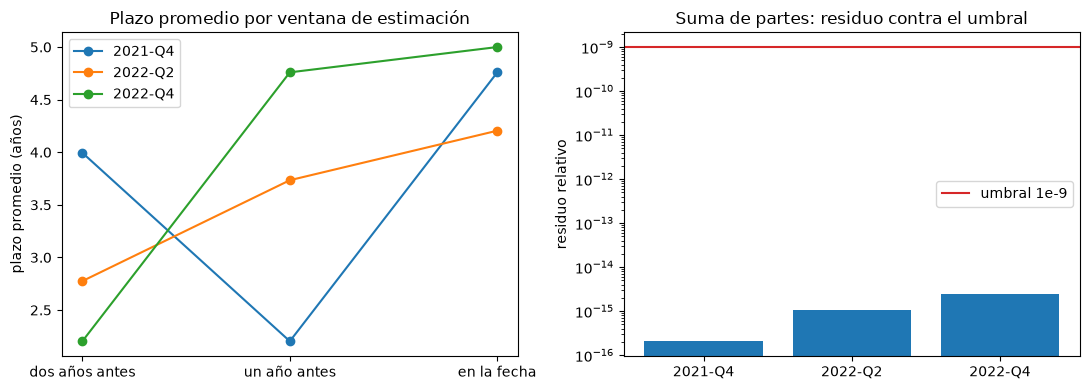

In [10]:
# Dibujar el plazo promedio por ventana de estimación y el residuo relativo de la suma de partes
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for q, (model, run) in windows.items():
    left.plot([1, 2, 3], run.extras["weighted_average_maturity"], marker="o", label=q)
left.set_xticks([1, 2, 3])
left.set_xticklabels(["dos años antes", "un año antes", "en la fecha"])
left.set_ylabel("plazo promedio (años)")
left.set_title("Plazo promedio por ventana de estimación")
left.legend()
residuals = [row_of(d, "irrbb.eve_sum_of_parts")["metric"] for d in docs.values()]
right.bar(list(docs), [max(r, 1e-18) for r in residuals], color="tab:blue")
right.axhline(1e-9, color="tab:red", label="umbral 1e-9")
right.set_yscale("log")
right.set_ylabel("residuo relativo")
right.set_title("Suma de partes: residuo contra el umbral")
right.legend()
fig.tight_layout()
plt.show()

## Resultados

- **Los valores de referencia.** Las dos pruebas de referencia son verdes e iguales a sus filas versionadas: el ejemplo resuelto del estándar tiene un estadístico de 0,0393 (el aplanamiento, a la precisión impresa) y el Anexo 1 chileno pasa 19 de 19 casos sin ninguno fallido. Dicen que la implementación reproduce lo que imprimen las fuentes; no dicen que las fuentes se apliquen bien a un balance.
- **La suma de partes.** El residuo relativo es del orden de 10^-15 en las tres fechas, seis órdenes de magnitud bajo el umbral de 10^-9, y las filas son iguales a las versionadas. Los controles muestran que la prueba está viva: un desplazamiento de una unidad en el todo (un cambio relativo de 1,4 x 10^-7) la pone en rojo con el umbral de 10^-9 y la deja en verde con un umbral de 10^-6, así que el umbral decide lo que la prueba puede ver; dejar una partida fuera da un residuo relativo de 2,03 y rojo. La prueba no puede ver un error que esté tanto en las partidas como en el todo.
- **La estabilidad de los pesos.** El plazo promedio de los depósitos mayoristas depende de la ventana en que se estima. En 2021-Q4 las tres ventanas dan 3,995, 2,204 y 4,759 años, una oscilación de 2,56 años entre ventanas consecutivas, y la luz es roja; en 2022-Q4 las ventanas dan 2,204, 4,759 y 5,000 años, roja otra vez; solo 2022-Q2, con 2,775, 3,734 y 4,205 años, es ámbar, con una distancia de 0,197 entre pesos. El valor que el banco informaría es el de la última ventana, así que la ventana es una palanca: una ventana más larga o una fecha final distinta mueve el plazo de los depósitos en años. Es el resultado más débil del caso, y el que un validador debe poner primero.
- **Las dos lecturas del EVE.** La prueba con y sin conducta es roja en las tres fechas, con estadísticos de 0,722, 0,562 y 0,466 del Tier 1 y sin exceso escondido: la medida conductual y la contractual están del mismo lado de la línea de 15 por ciento, pero muy separadas. Las filas versionadas son iguales, hash incluido.
- **El cambio ante un exceso.** El plazo promedio ponderado es 4,7595, 4,2049 y 5,0 años en las tres fechas y la prueba de valores atípicos estandarizada se supera en las tres. La prueba no se evalúa en la primera fecha (una sola fecha), es roja en la segunda (un cambio coincide con un exceso, el 2022-06-30) y roja en la tercera (dos cambios, el 2022-06-30 y el 2022-12-31). Las filas son iguales, hash incluido. Dos cautelas: todas las fechas están en exceso, y el parámetro es uno ajustado que se reestima en cada fecha, así que se mueve por construcción; el rojo dice que el patrón está presente, no que alguien eligiera el número para aliviar un exceso. El cuaderno 08 lo desarma.
- **La prueba fuera de muestra.** Ámbar en 2021-Q4 (16,2 por ciento) y `not_evaluated` en las otras dos fechas, donde el banco no presentó reportes posteriores. Toda la batería se lee entonces: referencias y suma de partes en verde, la prueba con y sin conducta en rojo, la estabilidad en rojo o ámbar, el cambio ante un exceso en rojo donde se puede evaluar, y la proyección en ámbar donde se puede comparar. En el banco sintético de C15 las mismas funciones dan verde para las referencias y la suma de partes de ambas monedas, y `not_evaluated` para la estabilidad, porque tiene una sola ventana de estimación.
- **Lo que afirman las pruebas.** Los umbrales son umbrales internos de Contraste, no umbrales regulatorios: un rojo es un hallazgo que leer, no un incumplimiento. Lo que no muestran es si un balance en verde es correcto; muestran que es internamente consistente.

## Resumen

- El motor guarda siete pruebas de validación de IRRBB; cada una es una función que devuelve un `TestResult`, declara su regla de luz y registra sus umbrales como umbrales internos de Contraste, nunca como regulación.
- Toda fila versionada se reproduce desde los insumos versionados; donde el documento guarda los insumos completos, el hash de los insumos también coincide, que es la prueba de que la fila es exactamente lo que se probó.
- Se muestra que una prueba no es vacía cambiando un insumo: un desplazamiento de una unidad del todo pone en rojo la suma de partes, un umbral más laxo la pone en verde, y una partida faltante la pone en rojo.
- La estabilidad de los pesos replicantes es el resultado más débil: roja en dos de tres fechas, con oscilaciones del plazo promedio de más de dos años entre ventanas.
- La prueba que marca un cambio de comportamiento ante un exceso es roja en dos fechas, y los pasos siguientes (cuaderno 08) examinan qué significa y qué no significa eso; la prueba fuera de muestra se evalúa en una sola fecha, porque el banco no presentó reportes posteriores.

**Qué probar a continuación.** Cambia `gap_amber` y `gap_red` en `nmd_parameter_stability` y mira qué fechas cambian de color. Después sigue con el cuaderno 06, el Anexo 1 chileno.

## Referencias

- BCBS, Standards: Interest rate risk in the banking book, SRP31.90 a SRP31.92 (el ejemplo resuelto), SRP31.82 a SRP31.83 y SRP31.129. https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book (la cartera replicante y la estabilidad de sus pesos). https://www.bis.org/bcbs/publ/d368.htm
- Board of Governors of the Federal Reserve System (2023), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- CMF, Recopilación Actualizada de Normas, capítulo 21-13, Anexo 1 (las fórmulas y tablas chilenas), según se transcriben en el dossier 03, F.2, y en la prueba de referencia del motor.
- FDIC, BankFind financials, dominio público. https://api.fdic.gov/banks/financials
- Departamento del Tesoro de EE. UU., Daily Treasury Par Yield Curve Rates, dominio público. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 05 de la investigación de Contraste, secciones D.3 y D.7.